In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

INPUT_FOLDER = "cxstack_push_full_rod_dats"


In [32]:
import re
from pathlib import Path

import scanpy as sc

PATTERN = re.compile(r"crxstack_K_(?P<k>[^_]+)_r0_(?P<r0>[^_]+)_seed_(?P<seed>[^.]+)\.dat$")


def _header_from_file(path: Path) -> list[str]:
    with path.open("r", encoding="utf-8") as handle:
        header_line = handle.readline().strip()
    return header_line.lstrip("#").split()


def load_cxstack_tables(input_folder: str):
    data = {}
    for path in Path(input_folder).glob("crxstack_K_*_r0_*_seed_*.dat"):
        match = PATTERN.match(path.name)
        if not match:
            continue
        columns = _header_from_file(path)
        df = sc.AnnData(
            pd.read_csv(path, sep=r"\s+", comment="#", names=columns, engine="python")
        ).to_df()
        data[(match["k"], match["r0"], match["seed"])] = df
    return data


cxstack_tables = load_cxstack_tables(INPUT_FOLDER)


c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\site-packages\legacy_api_wrap\__init__.py:82: UserWarning: X converted to numpy array with dtype float64
  return fn(*args_all, **kw)
c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\site-packages\legacy_api_wrap\__init__.py:82: UserWarning: X converted to numpy array with dtype float64
  return fn(*args_all, **kw)
c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\site-packages\legacy_api_wrap\__init__.py:82: UserWarning: X converted to numpy array with dtype float64
  return fn(*args_all, **kw)
c:\Users\Tristan\AppData\Local\Programs\Pytho

In [ ]:
def apply_moving_average(data_dict: dict, window: int):
    filtered = {}
    for key, df in data_dict.items():
        filtered[key] = df.rolling(window=window, min_periods=1).mean()
    return filtered


In [48]:
PAIR_COLUMNS = ["CXSTCK_pair1", "CXSTCK_pair2"]
MAF_WINDOW = 50


def max_pair_cxstack(data_dict: dict, pair_columns: list[str]):
    result = {}
    for key, df in data_dict.items():
        result[key] = pd.DataFrame({
            "step": df["step"],
            "cxstack": df[pair_columns].max(axis=1),
        })
    return result


cxstack_max_tables = max_pair_cxstack(cxstack_tables, PAIR_COLUMNS)

cxstack_MAF = apply_moving_average(cxstack_max_tables, MAF_WINDOW)


Text(0, 0.5, 'Max CXSTCK (MAF)')

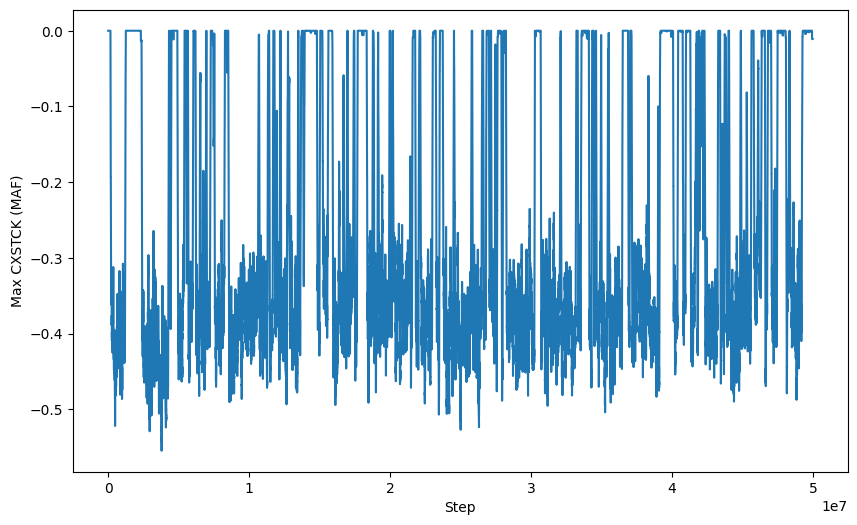

In [51]:
fig, ax = plt.subplots(figsize=(10, 6))
for key in [("015", "2", "1")]:
    df = cxstack_MAF[key]
    ax.plot(df["step"], df["cxstack"], label=f"{key}")

ax.set_xlabel("Step")
ax.set_ylabel("Max CXSTCK (MAF)")

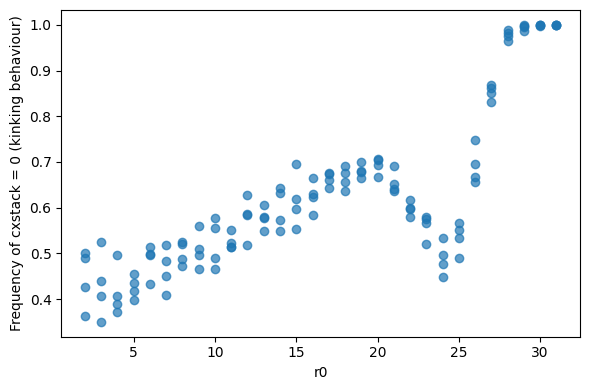

In [57]:
ZERO_TOL = 1e-9

r0_vals = []
zero_freqs = []

for (k, r0, seed), df in cxstack_max_tables.items():
    r0_vals.append(float(r0))
    zero_freqs.append(float(np.mean(np.isclose(df["cxstack"], 0.0, atol=ZERO_TOL))))

plt.figure(figsize=(6, 4))
plt.scatter(r0_vals, zero_freqs, alpha=0.7)
plt.xlabel("r0")
plt.ylabel("Frequency of cxstack = 0 (kinking behaviour)")
plt.tight_layout()
plt.show()
